# Atlas-DeePC: Component Ablations

**100 paired seeds per method: 211--310.** In this notebook, **Atlas-DeePC** always
means the algorithm in `baseline_graph_routed_atlas_deepc.ipynb`: 48 physical charts,
rank-60 **uncentered linear-subspace** bases, iterative **N=10 route-cost terminal
selection**, graph waypoints with the 7 cm terminal-mode latch, and the current-chart
DeePC matrix. There is no contextual atlas or rescue.

This notebook collects the small ablations in one place. Existing 100-seed results
are reused; the new experiment adds the literal constraint $\mathbf{1}^Tg=1$ to
the baseline's **SVD-basis coefficients**. Separate sections contain failure videos
without graph waypoints, paired outcomes, and solver-integrity checks.

All methods use the same frozen offline data, target/initial-state seeds, 320-step
rollouts, QP weights and actuator limits unless explicitly changed below. Strict
success requires mean error below 1 cm and maximum error below 2 cm in **both**
the final-30 and final-100 windows. No early termination is used. These seeds were
previously inspected; this is an exploratory paired study, not an untouched test set.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import sys
import json
import base64
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/small_atlas_ablations.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import small_atlas_ablations as experiment
import baseline_atlas_deepc as baseline
get_ipython().run_line_magic("matplotlib", "inline")
SEEDS = list(range(211, 311))
RUN_SUM_EXPERIMENT = False
RENDER_VIDEOS = False
WORKERS = 4
REPORT_DIR = experiment.RESULT_ROOT
if RUN_SUM_EXPERIMENT:
    experiment.run_sum_panel(SEEDS, workers=WORKERS)
if RENDER_VIDEOS:
    from render_small_atlas_ablations import render_all
    render_all()
    get_ipython().run_line_magic("matplotlib", "inline")
basis_payload = json.loads((experiment.BASIS_DIR / "summary.json").read_text())
sum_payload = json.loads((experiment.SUM_DIR / "summary.json").read_text())
nearest_payload = json.loads((experiment.NEAREST_DIR / "summary.json").read_text())
assert sum_payload["version"] == experiment.VERSION
assert basis_payload["version"] == "iterative_n10_geometry_waypoints_v1"
for payload in (sum_payload, nearest_payload):
    for key in ("config", "data_sha256", "atlas_sha256"):
        assert payload["signature"][key] == basis_payload["signature"][key]
assert basis_payload["signature"]["config"] == {k: v for k, v in vars(baseline.default_config()).items() if k != "seed"}
BASELINE = "Current Atlas-DeePC"
SUM_ONE = "Baseline + sum(SVD coefficients) = 1"
NEAREST = "Single nearest-fingertip reference"
AFFINE = "Centered affine charts + waypoints"
NO_WAYPOINTS = "No graph waypoints (linear charts)"
AFFINE_NO_WAYPOINTS = "Affine charts + no graph waypoints"
panels = {
    BASELINE: [r for r in basis_payload["results"] if r["method"] == "Linear charts + graph waypoints (baseline)"],
    SUM_ONE: sum_payload["results"],
    NEAREST: nearest_payload["results"],
    AFFINE: [r for r in basis_payload["results"] if r["method"] == "Affine charts + graph waypoints"],
    NO_WAYPOINTS: [r for r in basis_payload["results"] if r["method"] == "Linear charts + terminal reference only"],
    AFFINE_NO_WAYPOINTS: [r for r in basis_payload["results"] if r["method"] == "Affine charts + terminal reference only"],
}
def strict(row):
    return bool(row["success_30"] and row["success_100"])
for name, rows in panels.items():
    assert len(rows) == 100 and {r["seed"] for r in rows} == set(SEEDS), name
    assert all(r["steps"] == 320 and r["clusters"] == 48 and r["svd_rank"] == 60 for r in rows)
    assert all(r["minimum_selected_goal_source_separation"] >= 0.06 for r in rows)
    assert all(not r["fitted_dynamics_model"] and not r["feedback_fallback"] for r in rows)
baseline_by_seed = {r["seed"]: r for r in panels[BASELINE]}
print(f"Loaded {len(panels)} methods, each with 100 complete paired seeds (211--310).")


Loaded 6 methods, each with 100 complete paired seeds (211--310).


## 1. Results Overview

Only the named component changes in each single-component ablation. The last row
changes both centering and waypoint guidance. The nearest-reference variant retains
the 6 cm source-target eligibility filter and graph waypoints but fixes the single
closest eligible configuration. The no-waypoint variants retain iterative N=10
**graph-cost terminal selection**; they are not completely graph-free controllers.


,Changed component,Successes,Trials,Success rate (%),Median final-100 error (mm),Unsolved QP steps
Method,,,,,,
Current Atlas-DeePC,None: current baseline,93,100,93,2.062,0
Baseline + sum(SVD coefficients) = 1,Add one equality on the SVD coefficients,82,100,82,4.095,0
Single nearest-fingertip reference,Terminal-reference selection policy,90,100,90,1.665,0
Centered affine charts + waypoints,Chart centering / coordinate representation,91,100,91,2.185,0
No graph waypoints (linear charts),Remove graph waypoint references,83,100,83,2.440,0
Affine charts + no graph waypoints,Center charts and remove waypoints,81,100,81,2.409,0


,Repaired,Regressed,Net successes
Variant,,,
Baseline + sum(SVD coefficients) = 1,0,11,-11
Single nearest-fingertip reference,1,4,-3
Centered affine charts + waypoints,1,3,-2
No graph waypoints (linear charts),0,10,-10
Affine charts + no graph waypoints,0,12,-12


,Repaired,Regressed,Net successes,Repaired seeds,Regressed seeds
Variant,,,,,
Baseline + sum(SVD coefficients) = 1,0,11,-11,[],"[212, 216, 222, 233, 246, 277, 282, 290, 305, 306, 307]"
Single nearest-fingertip reference,1,4,-3,[299],"[231, 236, 290, 298]"
Centered affine charts + waypoints,1,3,-2,[296],"[231, 254, 266]"
No graph waypoints (linear charts),0,10,-10,[],"[236, 237, 241, 262, 269, 284, 292, 293, 294, 306]"
Affine charts + no graph waypoints,0,12,-12,[],"[231, 236, 237, 241, 254, 262, 266, 269, 284, 287, 293, 294]"


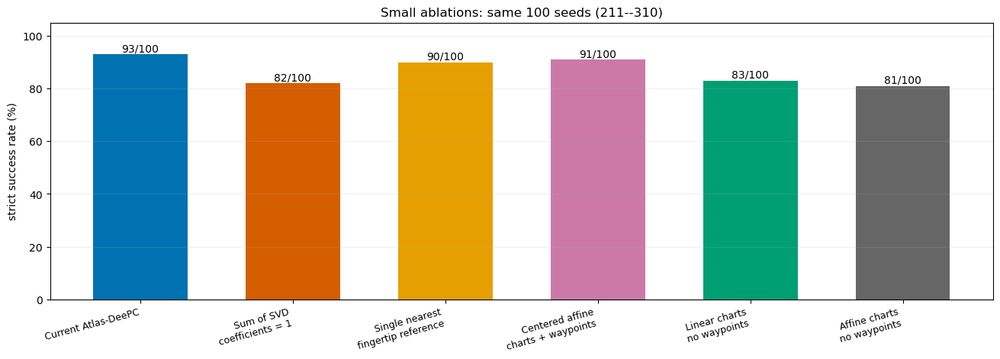

1557

In [2]:
changes = {
    BASELINE: "None: current baseline",
    SUM_ONE: "Add one equality on the SVD coefficients",
    NEAREST: "Terminal-reference selection policy",
    AFFINE: "Chart centering / coordinate representation",
    NO_WAYPOINTS: "Remove graph waypoint references",
    AFFINE_NO_WAYPOINTS: "Center charts and remove waypoints",
}
overview_rows = []
paired_rows = []
for name, rows in panels.items():
    count = sum(strict(r) for r in rows)
    overview_rows.append({"Method": name, "Changed component": changes[name], "Successes": count,
                          "Trials": 100, "Success rate (%)": count,
                          "Median final-100 error (mm)": 1000*np.median([r["mean_last_100"] for r in rows]),
                          "Unsolved QP steps": sum(r["unsolved_steps"] for r in rows)})
    if name != BASELINE:
        repaired = [r["seed"] for r in rows if strict(r) and not strict(baseline_by_seed[r["seed"]])]
        regressed = [r["seed"] for r in rows if not strict(r) and strict(baseline_by_seed[r["seed"]])]
        paired_rows.append({"Variant": name, "Repaired": len(repaired), "Regressed": len(regressed),
                            "Net successes": len(repaired)-len(regressed), "Repaired seeds": repaired,
                            "Regressed seeds": regressed})
overview = pd.DataFrame(overview_rows).set_index("Method")
display(overview.style.format({"Success rate (%)": "{:.0f}", "Median final-100 error (mm)": "{:.3f}"}))
paired = pd.DataFrame(paired_rows).set_index("Variant")
display(paired[["Repaired", "Regressed", "Net successes"]])
display(HTML("<details><summary>Paired repaired and regressed seed lists</summary>" + paired.to_html() + "</details>"))
colors = ["#0072B2", "#D55E00", "#E69F00", "#CC79A7", "#009E73", "#666666"]
labels = ["Current Atlas-DeePC", "Sum of SVD\ncoefficients = 1", "Single nearest\nfingertip reference",
          "Centered affine\ncharts + waypoints", "Linear charts\nno waypoints", "Affine charts\nno waypoints"]
fig, ax = plt.subplots(figsize=(13, 4.6), constrained_layout=True)
x = np.arange(len(panels))
ax.bar(x, overview["Success rate (%)"], color=colors, width=0.62)
for i, count in enumerate(overview.Successes):
    ax.text(i, count+1, f"{count}/100", ha="center")
ax.set(ylim=(0, 105), ylabel="strict success rate (%)", title="Small ablations: same 100 seeds (211--310)")
ax.set_xticks(x, labels, rotation=15, ha="right", fontsize=9)
ax.grid(axis="y", alpha=0.2)
fig.savefig(REPORT_DIR / "small_ablation_overview.png", dpi=170)
plt.show()
(REPORT_DIR / "overview.json").write_text(overview.reset_index().to_json(orient="records", indent=2))


## 2. New Ablation: Sum-to-One Constraint

For the current chart basis $B_{k_t}$, the baseline predicts the full input-output
trajectory as $b=B_{k_t}g$. This experiment adds exactly

$$\mathbf{1}^{T}g=1,\qquad g\in\mathbb{R}^{60}.$$

The existing empirical coefficient bounds, zero chart offset, coefficient penalty,
past-trajectory matching, input limits, and all tracking/control weights remain
unchanged. **No nonnegativity constraint is added**, so this is not a convex mixture.
All control steps still use N=10 terminal reselection and graph waypoints.

**Terminology matters:** here $g$ weights the retained SVD directions. The customary
affine combination of raw data columns instead uses $b=H\alpha$ and
$\mathbf{1}^{T}\alpha=1$. These are not the same constraint after SVD compression.
Even flipping the sign of one SVD vector changes the meaning of $\mathbf{1}^Tg=1$,
although it leaves the represented linear subspace unchanged. Consequently, this
tests a **coordinate-dependent slice of the cached subspace**, not affine DeePC in
general. It is also distinct from the centered affine-chart ablation in Section 1.

The existing QP implementation already supports this equality via the cached
matrix's `g_sum=1.0` setting. A wrapper records returned coefficient sums without
changing the objective or solver. Unsolved QPs, if any, retain the original runner's
zero-action handling and remain in the success denominator; they are not discarded.


In [3]:
display(overview.loc[[BASELINE, SUM_ONE], ["Successes", "Trials", "Success rate (%)", "Median final-100 error (mm)", "Unsolved QP steps"]].round(3))
display(paired.loc[[SUM_ONE]])
residuals = []
audited_steps = 0
for row in panels[SUM_ONE]:
    path = experiment.SUM_DIR / f"seed{row['seed']}_control_results.npz"
    with np.load(path, allow_pickle=True) as trace:
        solved = np.isin(trace["status"], ["optimal", "optimal_inaccurate"])
        sums = trace["coefficient_sum"]
        assert sums.shape == (320,) and np.array_equal(np.isfinite(sums), solved)
        residuals.extend(np.abs(sums[solved]-1).tolist())
        audited_steps += len(sums)
    assert row["initial_goal_index"] == baseline_by_seed[row["seed"]]["initial_goal_index"]
residuals = np.asarray(residuals)
display(pd.Series({"audited control steps": audited_steps, "solved QP steps": len(residuals),
                   "maximum |sum(g)-1|": float(residuals.max()) if len(residuals) else None,
                   "median |sum(g)-1|": float(np.median(residuals)) if len(residuals) else None,
                   "same initial terminal reference as baseline": True}))
if len(residuals):
    assert residuals.max() < 1e-5
delta = int(overview.loc[SUM_ONE, "Successes"]-overview.loc[BASELINE, "Successes"])
display(HTML(f"<p><strong>Observed result:</strong> the coefficient-sum constraint changes strict success "
             f"by {delta:+d} percentage points on this panel. This result applies to the fixed SVD "
             "coordinate system tested here; it should not be reported as a general verdict on affine data combinations.</p>"))


,Successes,Trials,Success rate (%),Median final-100 error (mm),Unsolved QP steps
Method,,,,,
Current Atlas-DeePC,93,100,93,2.062,0
Baseline + sum(SVD coefficients) = 1,82,100,82,4.095,0


,Repaired,Regressed,Net successes,Repaired seeds,Regressed seeds
Variant,,,,,
Baseline + sum(SVD coefficients) = 1,0,11,-11,[],"[212, 216, 222, 233, 246, 277, 282, 290, 305, ..."


audited control steps                          32000
solved QP steps                                32000
maximum |sum(g)-1|                               0.0
median |sum(g)-1|                                0.0
same initial terminal reference as baseline     True
dtype: object

## 3. What the Earlier Small Ablations Tested

- **Single nearest fingertip:** one closest eligible offline configuration is held
  fixed, instead of selecting among the N=10 candidates by route cost every step.
  Graph waypoint guidance is retained. Initial candidate eligibility is unchanged.
- **Centered affine charts:** use the chart mean plus a centered rank-60 SVD basis,
  instead of the baseline's zero-offset, uncentered basis. No sum-to-one equality is
  added in that experiment; the coefficient-bound rule is recalculated in its coordinates.
- **No graph waypoints:** feed the currently selected full terminal reference directly
  to DeePC from the first step, instead of following chart-medoid waypoints. N=10
  route-cost terminal selection and current-chart basis retrieval still operate.

Full geometry/waypoint details remain in `ablation_affine_subspace_and_graph_routing.ipynb`.
The nearest-reference study is also recorded in Section 4.3 of the baseline notebook.
The six rows in this notebook share the same 100-seed panel, not six independent datasets.


## 4. Paired Videos: With and Without Graph Waypoints

Each row pairs the **same seed**: **with graph waypoints on the left**, and
**without graph waypoints on the right**, both at **0.25x play speed**.
Successful clips end once the arm settles at the target, followed by a one-second
pause. We check the complete remaining trace: error stays below 1 cm, fingertip
movement stays within 1 mm of the clipping posture, and the joint cosine/sine
vector stays within 0.01. Failure clips retain all 320 steps, so later drift is not
hidden. All reported metrics still use the full, unchanged 320-step rollouts.

The dashboards show measured arm motion, the
selected terminal posture, current/goal chart histories, fingertip error, and applied
joint inputs. No hypothetical route is drawn in the no-waypoint videos.

**Seed 237** is a paired example: the baseline succeeds, while direct terminal-reference
tracking stays far from the target. **Seed 306** is another baseline success lost
without waypoints, with the target on the opposite side of the workspace.
**Seed 232** is a near-target failure under both methods, not a new failure caused
by removing waypoints. These examples are diagnostic selections, not an unbiased
sample of videos; success rates above use all 100 trials.

The final three pairs show **both methods succeeding**: **seed 212** has a
lower-left target, **seed 213** an upper target, and **seed 222** a target near
the arm base. They are selected for different target locations, not as a random
sample. In all three, the baseline actually uses graph waypoints before switching
to the terminal reference; the paired trajectories can differ despite both succeeding.



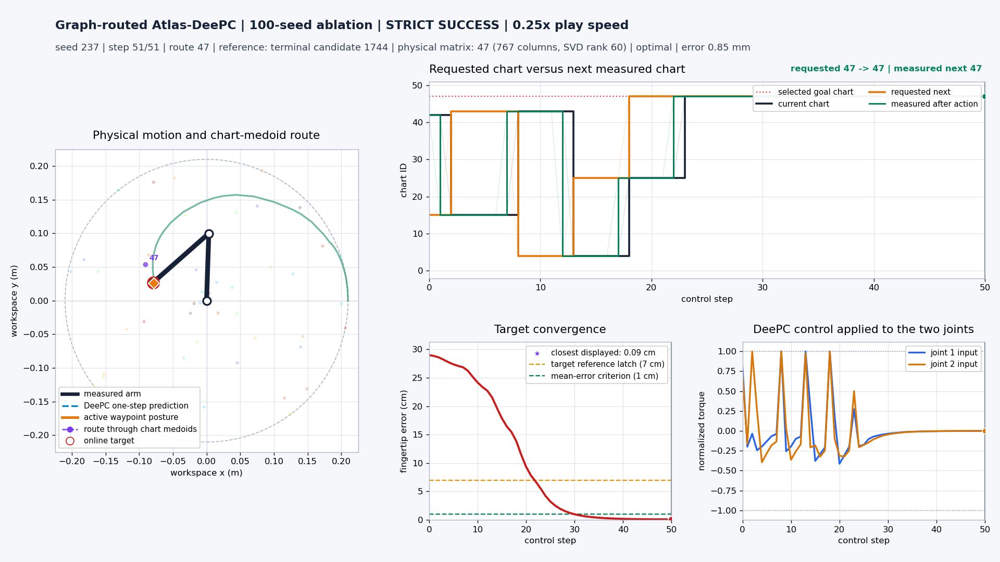
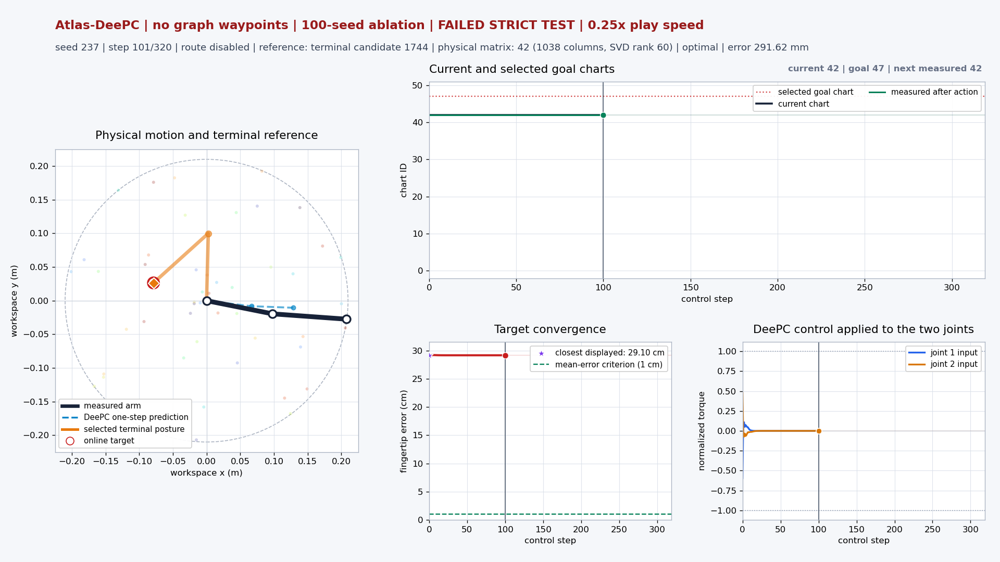


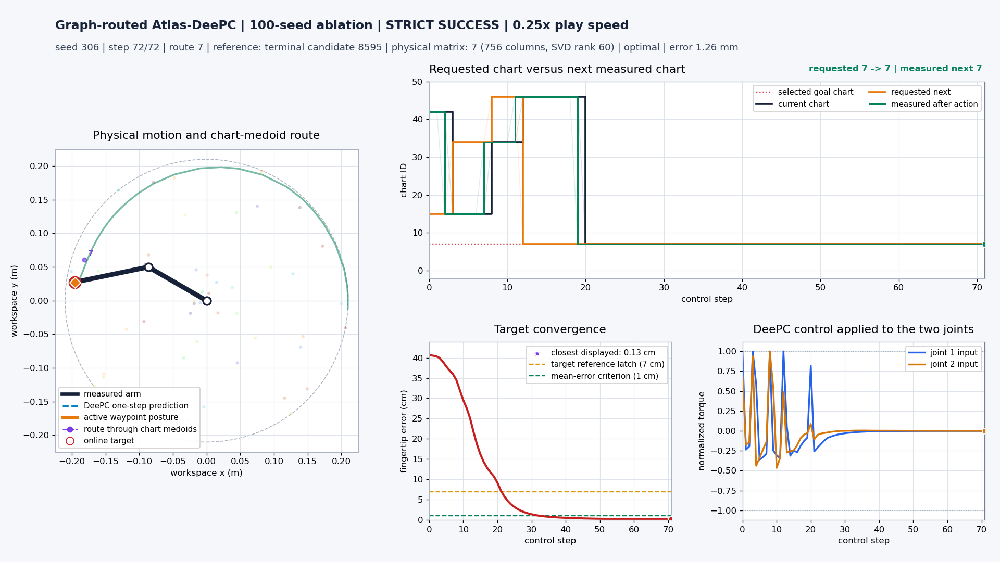
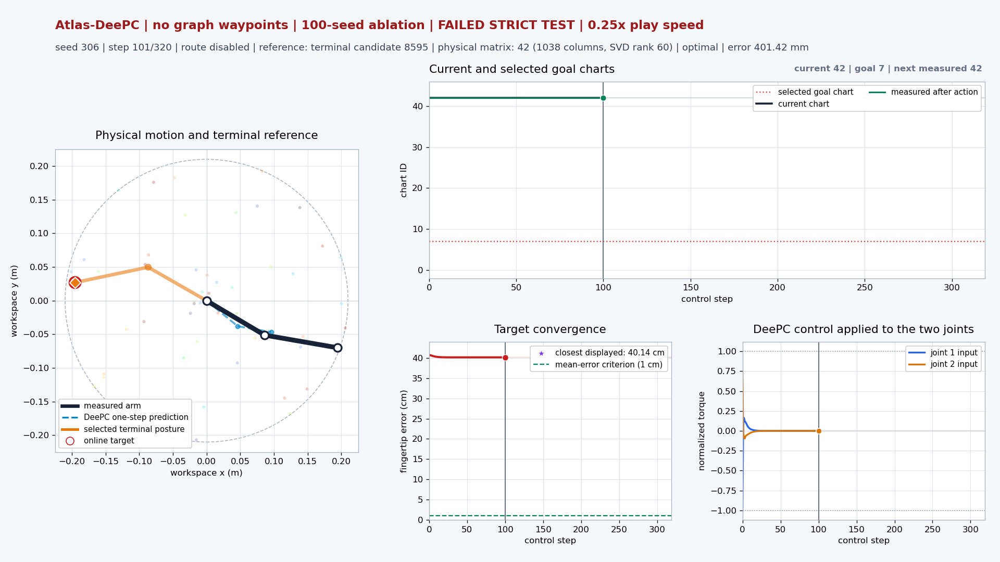


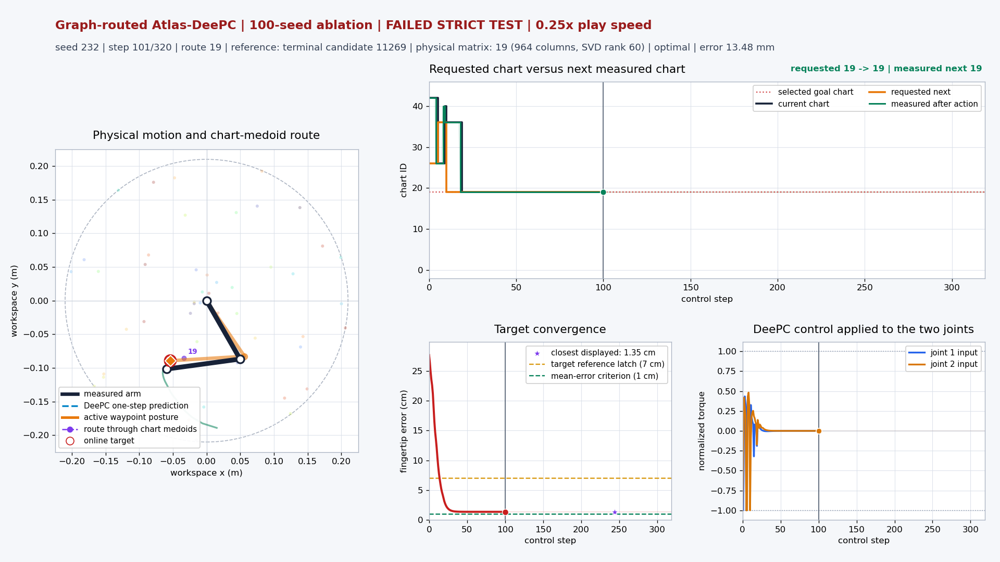
...
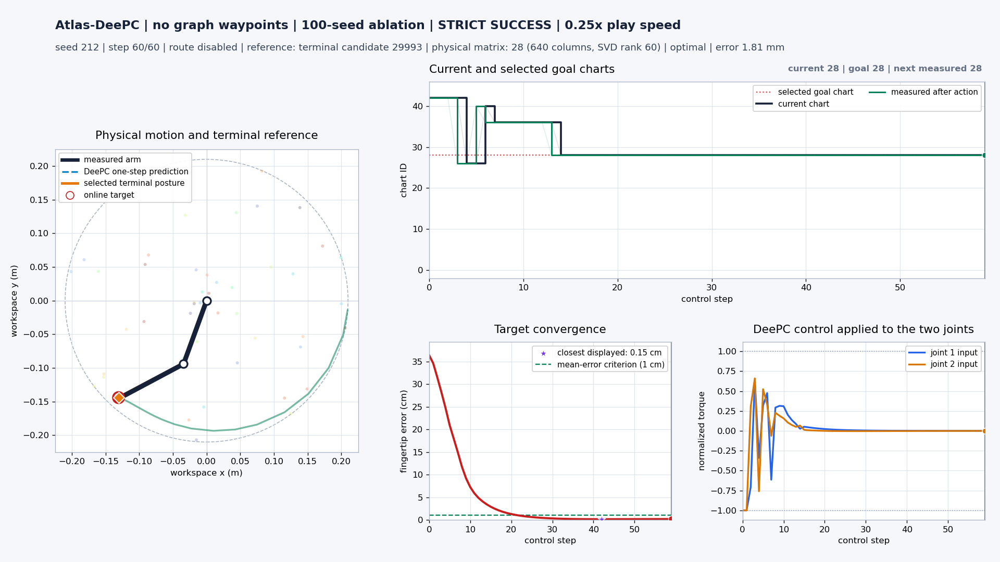


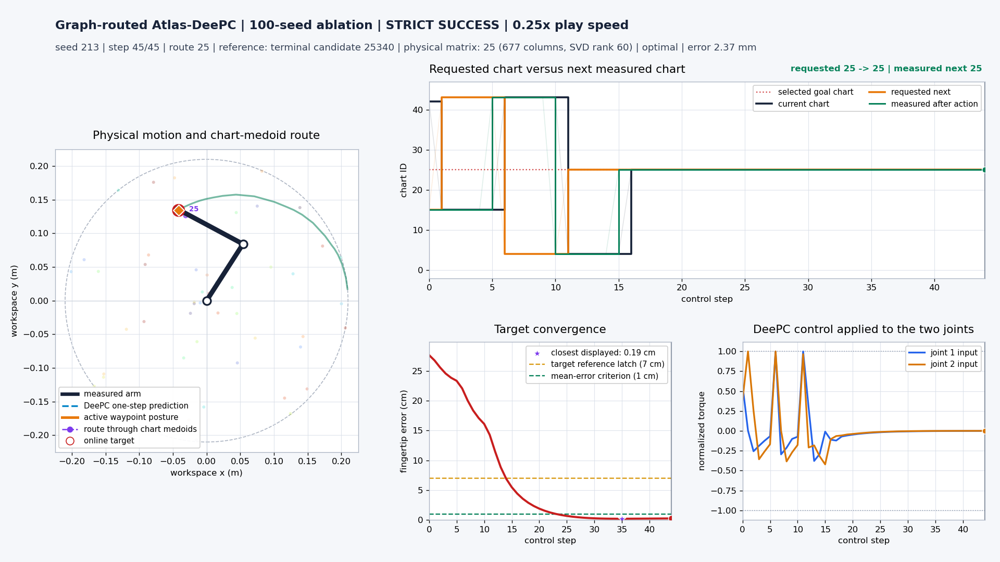
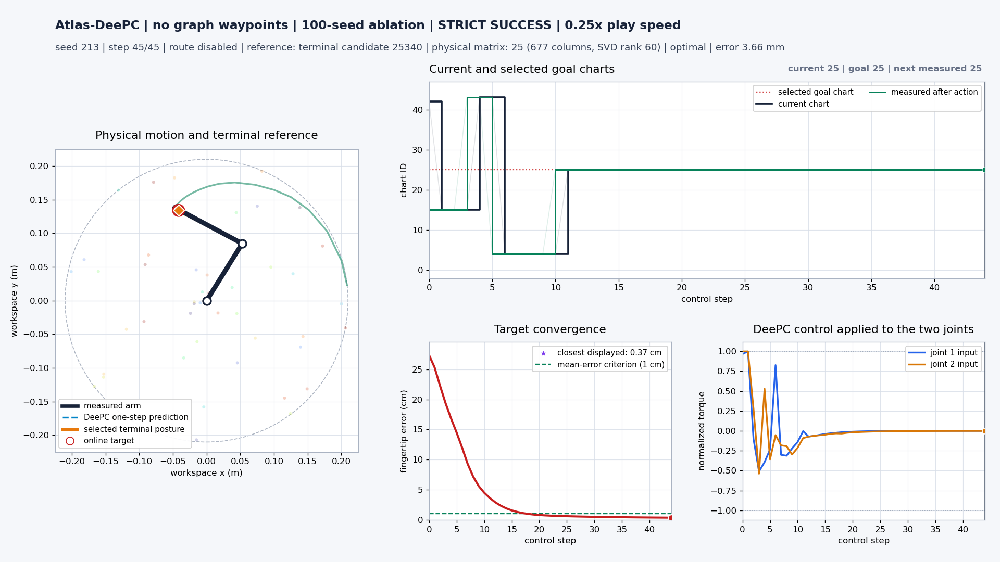


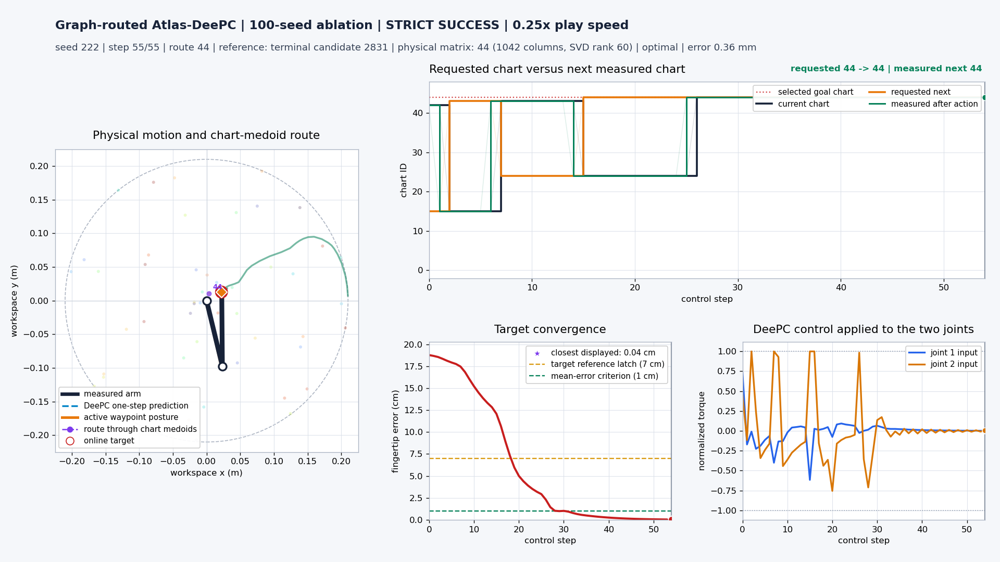
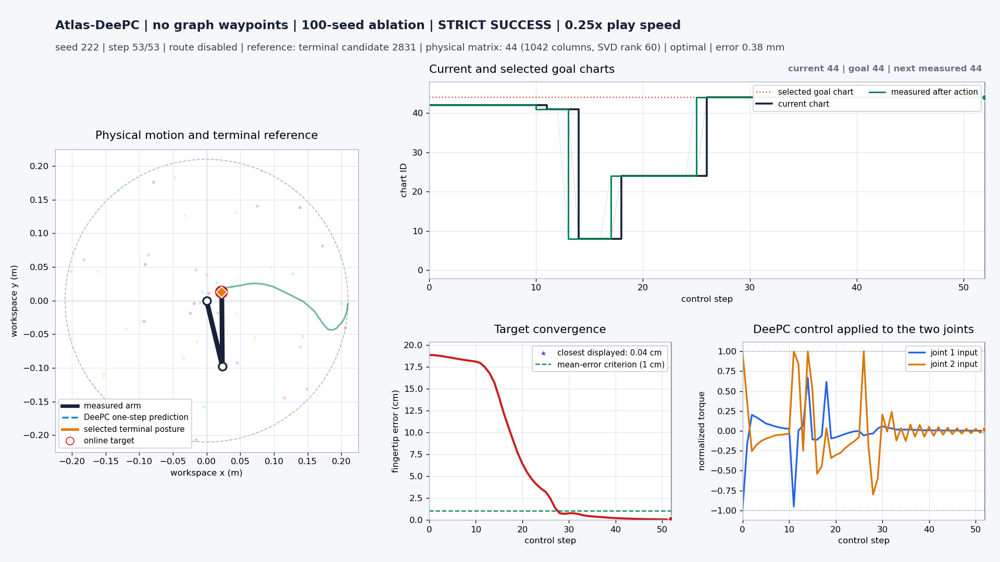

In [4]:
VIDEO_DIR = REPORT_DIR / "videos"
video_entries = json.loads((VIDEO_DIR / "manifest.json").read_text())
video_lookup = {(r["seed"], r["variant"]): r for r in video_entries}
def video_card(seed, variant, caption):
    entry = video_lookup[(seed, variant)]
    video = VIDEO_DIR / Path(entry["video"]).name
    poster = VIDEO_DIR / Path(entry["poster"]).name
    source = experiment.BASIS_DIR / variant / f"seed{seed}_control_results.npz"
    from candidate_goal_routing_experiment import file_digest
    assert entry["metadata"]["source_result_sha256"] == file_digest(source)
    assert entry["metadata"]["saved_control_steps"] == 320
    assert 2 <= entry["metadata"]["displayed_control_steps"] <= 320
    assert entry["metadata"]["graph_waypoints_used"] == (variant == "linear_graph")
    with np.load(source, allow_pickle=True) as trace:
        row = json.loads(trace["summary"].item())
    result = "STRICT SUCCESS" if strict(row) else "FAILED STRICT TEST"
    shown = entry["metadata"]["displayed_control_steps"]
    clip_note = f"Shown: {shown}/320 steps; trimmed after settling" if shown < 320 else "Full 320-step rollout"
    mp4 = base64.b64encode(video.read_bytes()).decode("ascii")
    png = base64.b64encode(poster.read_bytes()).decode("ascii")
    return (f'<div style="min-width:0;background:white;color:#172238;padding:12px;border:1px solid #cbd5e1">'
            f'<h3 style="margin:0 0 8px;color:#172238">Seed {seed}: {caption}</h3>'
            f'<p style="margin:0 0 8px;color:#344054">{result}; final-100 mean {1000*row["mean_last_100"]:.3f} mm</p>'
            f'<p style="margin:0 0 8px;color:#344054">{clip_note}</p>'
            f'<video controls preload="none" style="width:100%" poster="data:image/png;base64,{png}" '
            f'src="data:video/mp4;base64,{mp4}"></video></div>')
for seed in (237, 306, 232):
    display(HTML('<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:14px;margin-bottom:20px">'
                 + video_card(seed, "linear_graph", "with graph waypoints")
                 + video_card(seed, "linear_terminal", "without graph waypoints") + '</div>'))
display(HTML('<h3>Cases where both methods succeed</h3>'))
for seed in (212, 213, 222):
    for method in (BASELINE, NO_WAYPOINTS):
        assert strict(next(row for row in panels[method] if row["seed"] == seed))
    display(HTML('<div style="display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:14px;margin-bottom:20px">'
                 + video_card(seed, "linear_graph", "with graph waypoints")
                 + video_card(seed, "linear_terminal", "without graph waypoints") + '</div>'))


## 5. New-Experiment Timing and Reproduction

The coefficient-sum experiment uses four worker processes with one numerical-library
thread each. Timings are pooled over 31,500 steps after excluding the first five
steps of each rollout; no separate warm-up rollout was run. The machine was shared
with video rendering and other work. These measurements are **not an isolated
cross-method latency benchmark**. The original per-step timers are retained.


,mean_ms,median_ms,p95_ms,p99_ms
module,,,,
Chart localization,0.0820,0.0661,0.1313,0.3622
Terminal-reference selection,0.0193,0.0150,0.0227,0.0806
Graph routing,0.0080,0.0061,0.0110,0.0342
Linear subspace retrieval,0.0010,0.0007,0.0011,0.0018
QP construction and solve,42.0272,37.9871,64.4247,93.2188
Other control-loop work,0.0373,0.0295,0.0563,0.1446
Total online control,42.1748,38.1289,64.5704,93.3776


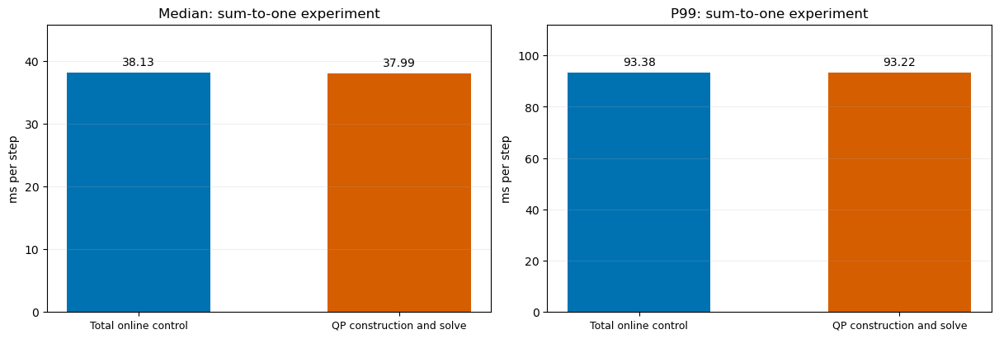

In [5]:
timing = pd.DataFrame(sum_payload["timing"]["modules"]).set_index("module")
assert sum_payload["timing"]["timed_steps"] == 31500
display(timing[["mean_ms", "median_ms", "p95_ms", "p99_ms"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
main = timing.loc[["Total online control", "QP construction and solve"]]
x = np.arange(len(main))
for ax, key, label in zip(axes, ["median_ms", "p99_ms"], ["Median", "P99"]):
    bars = ax.bar(x, main[key], color=["#0072B2", "#D55E00"], width=0.55)
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.set_xticks(x, main.index, fontsize=9)
    ax.set(ylim=(0, main[key].max()*1.2), ylabel="ms per step", title=f"{label}: sum-to-one experiment")
    ax.grid(axis="y", alpha=0.2)
fig.savefig(REPORT_DIR / "sum_constraint_timing.png", dpi=160)
plt.show()


To run/resume the new 100-seed experiment and regenerate the videos:

```bash
python src/small_atlas_ablations.py --workers 4
python src/render_small_atlas_ablations.py
```

The notebook defaults to reading saved results and embedded videos. New results live
in `experiments/routed_deepc_iid/small_current_atlas_100/`; earlier ablation data remain
in their own folders. The main baseline notebook and its algorithm are not replaced.
Future small studies can be added as separate sections using the same 100-seed panel.
